**Proyecto 1: Análisis de señales ECG y detección de arritmias**

**Integrantes:** Paula García · Valentina Morales


**Fecha de entrega:**

---

 **1.1 Diagramas de flujo**

Artículo 1. Gadaleta et al. (2023), *npj Digital Medicine*
Predicción de fibrilación auricular a 2 semanas a partir de ECG de una derivación sin arritmias.

![Diagrama artículo 1](diagrama_articulo1.png)

Artículo 2. Zheng et al. (2020), *Scientific Reports*
Clasificación multietapa de arritmias (base Chapman).

![Diagrama artículo 2](diagrama_articulo2.png)

Artículo 3. Liu et al. (2024), *Heliyon*
Clasificación de arritmias con CNN sobre ECG de una derivación, sin detección del QRS.

![Diagrama artículo 3](diagrama_articulo3.png)

---

**1.2 Explicación de las metodologías con nuestras palabras**

**Artículo 1:** La fibrilación auricular es una arritmia en la que las aurículas laten de manera descontrolada. Es difícil de detectar con métodos tradicionales porque puede aparecer y desaparecer de forma súbita e impredecible, por lo que ni un electrocardiograma de diez segundos, ni siquiera un Holter de veinticuatro horas garantizan capturar un episodio, ya que no se sabe cuándo va a ocurrir.

Frente a ese problema, el artículo propone un modelo que recibe ventanas de ECG de diez minutos y predice si la persona podría tener un episodio de fibrilación auricular en las siguientes dos semanas, aunque el ECG analizado no muestre ningún signo de la arritmia. Se usan ventanas de diez minutos por un tema de costo computacional, ya que es mucho más manejable para los modelos procesar esa cantidad de datos que la señal completa de veinticuatro horas de una sola vez.

El primer modelo se entrena con cada ventana de forma independiente y extrae ciento veintiocho parámetros propios de la morfología de la señal, que no corresponden a fórmulas definidas por médicos o estadísticos, sino a patrones que el modelo considera relevantes durante su entrenamiento. Además, para cada ventana también se calculan estadísticos ya conocidos, como la variabilidad del ritmo cardíaco y la cantidad de latidos ectópicos. En total, un día se divide en ciento cuarenta y cuatro ventanas, y por cada una se obtiene un paquete que combina los ciento veintiocho parámetros de la red con los estadísticos tradicionales. Esa secuencia completa de ventanas se le pasa al segundo modelo, que la procesa en orden temporal y decide qué tan en riesgo está la persona de sufrir fibrilación auricular.
Para evaluar el desempeño se usa el *AUC*, un índice que indica qué tan bien distingue el modelo entre una persona que va a tener fibrilación auricular y una que no, y que va de 0.5, equivalente al azar, a 1, que sería un modelo perfecto.
Usando solamente edad y sexo, el *AUC* es de 0.67; agregando la variabilidad del ritmo cardíaco sube a 0.74; y utilizando todos los datos disponibles, incluyendo los ciento veintiocho parámetros de la red neuronal y los estadísticos tradicionales, llega a 0.80.

Sin embargo, de la cohorte estudiada solo el 4.3% de las personas tuvo realmente un episodio de fibrilación auricular durante esas dos semanas. Esa baja prevalencia hace que, aunque el modelo tenga una sensibilidad del 0.80, su precisión sea naturalmente baja, de apenas 0.09, lo que significa que se generan muchos falsos positivos: de cada cien alertas de riesgo alto, solo nueve corresponden a casos reales de fibrilación auricular.

**Artículo 2:** Las arritmias cardíacas se diagnostican con un electrocardiograma, pero interpretarlo depende de que un cardiólogo lo revise, lo que toma tiempo y limita la detección a gran escala. El artículo propone un método automático que, a partir de un ECG, clasifica el ritmo que el paciente tiene en ese momento (no predice lo que pueda pasar en el futuro) en cuatro grupos: bradicardia sinusal, fibrilación o aleteo auricular, taquicardias supraventriculares y ritmo sinusal.

Se usó una base de datos de más de cuarenta mil pacientes, con ECG de doce derivaciones de diez segundos, donde los ritmos fueron diagnosticados por cardiólogos. Originalmente había once ritmos distintos, y se agruparon en cuatro según su relevancia clínica, porque algunos tenían muy pocos casos para entrenar un modelo.

Primero se limpia la señal en tres pasos: un filtro pasa-bajas que elimina el ruido de alta frecuencia, un método llamado LOESS robusto que corrige el movimiento lento de la línea base, por debajo de 0.5 Hz, y un tercer método, Non Local Means, que quita el ruido que queda. Después se detectan los picos y valles de la señal, que se clasifican en complejos QRS, picos que no son QRS y valles, y de cada uno se miden la altura, el ancho y la prominencia. También se comparan estos elementos por pares y se calculan razones respecto al tiempo entre ellos.

El problema es que cada paciente tiene un número distinto de latidos, y por lo tanto de picos y valles, pero el modelo necesita que todos los pacientes tengan la misma cantidad de datos. Por eso cada variable se resume en un histograma de cien intervalos, que cuenta cuántas veces aparece cada rango de valores. Se usa un histograma y no un promedio porque el promedio pierde la forma de la distribución: dos pacientes pueden tener el mismo valor promedio pero comportamientos muy distintos, y el histograma sí lo captura.

Con esos datos se compararon diecinueve algoritmos de clasificación combinados con cinco estrategias, ajustando sus parámetros y validando con validación cruzada de diez partes. Los mejores fueron los árboles con gradient boosting. En el boosting los árboles se construyen uno tras otro, y cada uno intenta corregir los errores del anterior, a diferencia del bagging, donde los árboles se entrenan de forma independiente y se promedian. Con este método el *F1-score* fue de 0.988 en pacientes sin otras condiciones cardíacas y de 0.97 en pacientes que sí las tenían. El F1 combina la precisión y la sensibilidad, por lo que un valor alto indica que el modelo clasifica bien sin sacrificar ninguna de las dos.

También se probó el método en la base MIT-BIH y se obtuvo un *F1-score* de 0.992, aunque ahí la tarea fue clasificar latidos individuales y no ritmos, por lo que no es una validación del mismo problema. Otra limitación es que el artículo no aclara en cuál de los cuatro grupos queda la taquicardia sinusal, que representa más del 15% de los pacientes, y que la afirmación de desempeño comparable al de cardiólogos no se midió directamente contra ellos.

**Artículo 3:** Muchos métodos de clasificación de arritmias dependen de detectar primero el complejo QRS, para medir intervalos entre latidos y calcular rasgos a partir de ahí. El problema es que esa detección falla fácilmente cuando la señal tiene ruido o movimiento, que es lo que pasa con los dispositivos portátiles. El artículo propone un método que clasifica arritmias directamente sobre la señal, sin detectar el QRS, usando una red neuronal convolucional.

Se usan señales de una sola derivación de tres bases de datos de PhysioNet, con nueve ritmos cardíacos: ritmo sinusal normal, fibrilación auricular, aleteo auricular, Wolff-Parkinson-White, bloqueo Mobitz II, bradicardia sinusal, taquicardia ventricular, fibrilación ventricular y aleteo ventricular. Como las bases venían con frecuencias de muestreo distintas, todas se llevaron a 250 Hz. Luego las señales se cortaron en segmentos de cinco y de diez segundos, y para aumentar el número de muestras se usaron ventanas superpuestas, es decir, segmentos que comparten una parte de la señal con el siguiente.

La red recibe el segmento completo y tiene cuatro capas convolucionales, con max pooling entre ellas. La primera capa detecta patrones simples de la señal, y las siguientes los van combinando en estructuras cada vez más complejas. El max pooling reduce el tamaño de lo que se procesa y conserva lo más relevante. Al final, capas totalmente conectadas y una función softmax dan la probabilidad de que el segmento corresponda a cada uno de los nueve ritmos.

Con segmentos de cinco segundos la exactitud fue de 96.51%, y con diez segundos de 98.1%. Además, el modelo de cinco segundos se probó con una base distinta, CUDB, que no se usó para entrenar y en la que se emplearon los ritmos completos sin solapamiento, y ahí la exactitud bajó a 91.6%. Una de las confusiones más frecuentes fue clasificar fibrilación auricular como aleteo auricular.

Hay varias limitaciones. Con ventanas superpuestas puede haber fuga de datos: si una ventana queda en entrenamiento y otra, que comparte parte de la misma señal, queda en validación, el modelo estaría evaluándose con algo que ya vio casi igual, lo que inflaría la exactitud interna. El artículo no aclara cómo se dividieron los datos, así que esto es una posibilidad y no algo confirmado. Eso encaja con que la exactitud baje en la prueba externa.

---

**2.1 Carga y revisión general de los datos**

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import signal, stats
from pathlib import Path

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

RUTA_DIAGNOSTICS = Path("Diagnostics.xlsx")  
RUTA_SENALES = Path("ECGDataDenoised")     

df = pd.read_excel(RUTA_DIAGNOSTICS)

print(df.shape)
display(df.head())
display(df.dtypes)

# faltantes y duplicados
print(df.isna().sum().sum(), "faltantes;", df.duplicated().sum(), "filas duplicadas;",
      df["FileName"].duplicated().sum(), "FileName repetidos")

# resumen numérico y categórico
display(df.describe().T)
for c in ["Rhythm", "Gender"]:
    display(df[c].value_counts())
print("Beat:", df["Beat"].nunique(), "combinaciones;", (df["Beat"] == "NONE").mean().round(3), "es NONE")

# chequeos de rango
print("menores de 18:", (df.PatientAge < 18).sum())
print("QRS < 40 ms:", (df.QRSDuration < 40).sum())
print("AtrialRate == 0:", (df.AtrialRate == 0).sum())

(10646, 16)


,FileName,Rhythm,Beat,PatientAge,Gender,VentricularRate,AtrialRate,QRSDuration,QTInterval,QTCorrected,RAxis,TAxis,QRSCount,QOnset,QOffset,TOffset
0,MUSE_20180113_171327_27000,AFIB,RBBB TWC,85,MALE,117,234,114,356,496,81,-27,19,208,265,386
1,MUSE_20180112_073319_29000,SB,TWC,59,FEMALE,52,52,92,432,401,76,42,8,215,261,431
2,MUSE_20180111_165520_97000,SA,NONE,20,FEMALE,67,67,82,382,403,88,20,11,224,265,415
3,MUSE_20180113_121940_44000,SB,NONE,66,MALE,53,53,96,456,427,34,3,9,219,267,447
4,MUSE_20180112_122850_57000,AF,STDD STTC,73,FEMALE,162,162,114,252,413,68,-40,26,228,285,354


FileName           object
Rhythm             object
Beat               object
PatientAge          int64
Gender             object
VentricularRate     int64
AtrialRate          int64
QRSDuration         int64
QTInterval          int64
QTCorrected         int64
RAxis               int64
TAxis               int64
QRSCount            int64
QOnset              int64
QOffset             int64
TOffset             int64
dtype: object

0 faltantes; 0 filas duplicadas; 0 FileName repetidos


,count,mean,std,min,25%,50%,75%,max
PatientAge,10646.0,59.186831,18.030019,4.0,49.0,62.0,72.0,98.0
VentricularRate,10646.0,84.136107,34.455349,34.0,57.0,73.0,104.0,263.0
AtrialRate,10646.0,92.577870,60.093940,0.0,57.0,72.0,106.0,535.0
QRSDuration,10646.0,90.989292,17.479540,18.0,80.0,88.0,98.0,256.0
QTInterval,10646.0,384.150855,59.226289,114.0,344.0,390.0,426.0,736.0
QTCorrected,10646.0,434.154048,39.354182,219.0,408.0,430.0,456.0,760.0
RAxis,10646.0,39.620609,41.212648,-89.0,14.0,46.0,68.0,270.0
TAxis,10646.0,44.637704,57.478092,-89.0,19.0,42.0,62.0,270.0
QRSCount,10646.0,13.839470,5.676339,5.0,9.0,12.0,17.0,40.0
QOnset,10646.0,219.260567,6.410413,159.0,216.0,219.0,224.0,240.0


Rhythm
SB       3889
SR       1826
AFIB     1780
ST       1568
SVT       587
AF        445
SA        399
AT        121
AVNRT      16
AVRT        8
SAAWR       7
Name: count, dtype: int64

Gender
MALE      5956
FEMALE    4690
Name: count, dtype: int64

Beat: 742 combinaciones; 0.509 es NONE
menores de 18: 265
QRS < 40 ms: 1
AtrialRate == 0: 12


La base `Diagnostics.xlsx` contiene 10.646 registros, uno por paciente, y 16 variables: el nombre del archivo de la señal (`FileName`), el ritmo cardíaco (`Rhythm`), otras condiciones del ECG (`Beat`), la edad, el sexo y 11 mediciones del electrocardiograma, entre ellas las frecuencias ventricular y auricular, la duración del QRS, los intervalos QT y los ejes eléctricos. No hay valores faltantes ni registros duplicados, y cada `FileName` es único, lo que permite emparejar cada fila con su señal.

Hay 11 ritmos: SB (bradicardia sinusal), SR (ritmo sinusal), ST (taquicardia sinusal), AFIB (fibrilación auricular), AF (aleteo auricular), SA (irregularidad sinusal), SVT (taquicardia supraventricular), AT (taquicardia auricular), AVNRT, AVRT y SAAWR (marcapasos auricular errante).

La edad de los pacientes tiene una media de 59 años (desviación estándar de 18), una mediana de 62 y va de 4 a 98 años. El 56% son hombres (5.956) y el 44% mujeres (4.690). La frecuencia ventricular media es de 84 latidos por minuto y la duración media del QRS es de 91 ms. El ritmo más frecuente es la bradicardia sinusal, y tres ritmos (SB, SR y AFIB) concentran cerca del 70% de los registros, mientras que AVNRT, AVRT y SAAWR tienen menos de 20 registros cada uno.

Como observaciones sobre la calidad de los datos: hay 265 pacientes menores de 18 años, un registro con una duración del QRS de 18 ms, que es fisiológicamente imposible y probablemente un error de medición, y la columna `Beat` contiene 742 combinaciones de condiciones adicionales, de las cuales el 51% corresponde a `NONE`. Estos aspectos se tendrán en cuenta en los análisis siguientes.

---

**2.2 ¿Qué tipo de arritmias son más prevalentes?**

,n,%
Rhythm,,
SB,3889,36.53
SR,1826,17.15
AFIB,1780,16.72
ST,1568,14.73
SVT,587,5.51
AF,445,4.18
SA,399,3.75
AT,121,1.14
AVNRT,16,0.15


,n,% de arritmias
Rhythm,,
SB,3889,44.09
AFIB,1780,20.18
ST,1568,17.78
SVT,587,6.66
AF,445,5.05
SA,399,4.52
AT,121,1.37
AVNRT,16,0.18
AVRT,8,0.09


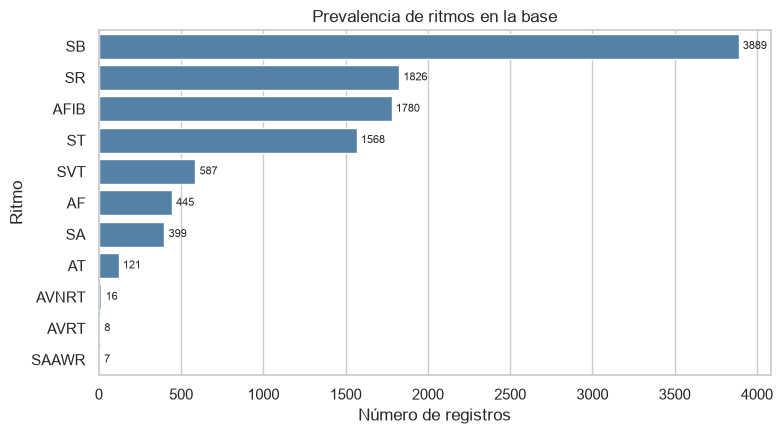

In [5]:
# Prevalencia de los 11 ritmos
prev = df["Rhythm"].value_counts().to_frame("n")
prev["%"] = (100 * prev["n"] / len(df)).round(2)
display(prev)

# Sin SR (ritmo normal): solo arritmias
arr = df[df["Rhythm"] != "SR"]
prev_arr = arr["Rhythm"].value_counts().to_frame("n")
prev_arr["% de arritmias"] = (100 * prev_arr["n"] / len(arr)).round(2)
display(prev_arr)

# Gráfico
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.countplot(data=df, y="Rhythm", order=prev.index, color="steelblue", ax=ax)
for p in ax.patches:
    ax.annotate(f"{int(p.get_width())}", (p.get_width(), p.get_y() + p.get_height() / 2),
                va="center", ha="left", fontsize=8, xytext=(3, 0), textcoords="offset points")
ax.set_xlabel("Número de registros")
ax.set_ylabel("Ritmo")
ax.set_title("Prevalencia de ritmos en la base")
plt.tight_layout()
plt.show()

El ritmo más frecuente en la base es la bradicardia sinusal (SB), con 3.889 registros (36,5% del total). Le siguen el ritmo sinusal normal (SR, 17,2%), la fibrilación auricular (AFIB, 16,7%) y la taquicardia sinusal (ST, 14,7%). Estos cuatro ritmos concentran el 85% de la base. Los demás son menos frecuentes: la taquicardia supraventricular (SVT) representa el 5,5%, el aleteo auricular (AF) el 4,2% y la irregularidad sinusal (SA) el 3,8%, mientras que AT, AVNRT, AVRT y SAAWR están por debajo del 1,2%.

Como SR es el ritmo normal y no una arritmia, al excluirlo (8.820 registros) las arritmias más prevalentes son la bradicardia sinusal (44,1%), la fibrilación auricular (20,2%) y la taquicardia sinusal (17,8%).

---

**2.3 ¿Hay arritmias más prevalentes para un género específico?**


Gender,FEMALE,MALE,total,% hombres,% mujeres
Rhythm,,,,,
SB,1408,2481,3889,63.8,36.2
SR,1024,802,1826,43.9,56.1
AFIB,739,1041,1780,58.5,41.5
ST,769,799,1568,51.0,49.0
SVT,308,279,587,47.5,52.5
AF,188,257,445,57.8,42.2
SA,176,223,399,55.9,44.1
AT,57,64,121,52.9,47.1
AVNRT,12,4,16,25.0,75.0


% de hombres en toda la base: 55.9%


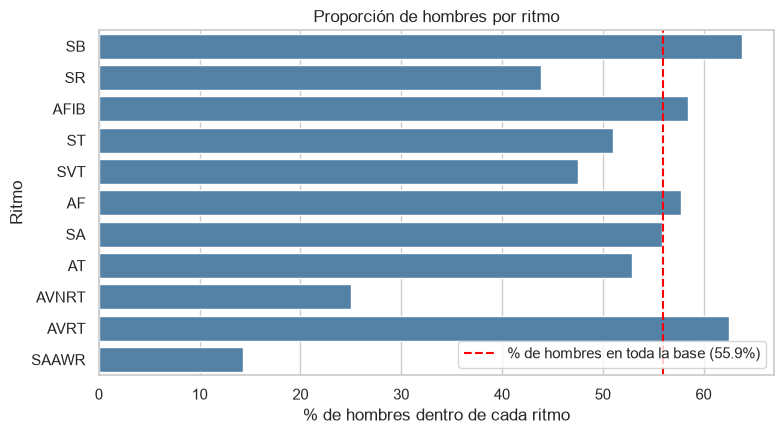

In [6]:
# Tabla ritmo x sexo
orden = df["Rhythm"].value_counts().index
ct = pd.crosstab(df["Rhythm"], df["Gender"]).loc[orden, ["FEMALE", "MALE"]]
ct["total"] = ct.sum(axis=1)
ct["% hombres"] = (100 * ct["MALE"] / ct["total"]).round(1)
ct["% mujeres"] = (100 * ct["FEMALE"] / ct["total"]).round(1)
display(ct)

base_h = 100 * (df["Gender"] == "MALE").mean()
print(f"% de hombres en toda la base: {base_h:.1f}%")

# Gráfico: % de hombres por ritmo
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=ct.reset_index(), y="Rhythm", x="% hombres", order=orden, color="steelblue", ax=ax)
ax.axvline(base_h, color="red", linestyle="--", label=f"% de hombres en toda la base ({base_h:.1f}%)")
ax.set_xlabel("% de hombres dentro de cada ritmo")
ax.set_ylabel("Ritmo")
ax.set_title("Proporción de hombres por ritmo")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

El 55,9% de los registros de la base de datos corresponde a hombres, por lo que se compara la proporción de hombres de cada ritmo contra ese valor. 

La bradicardia sinusal es más frecuente en hombres (63,8%). En mujeres son más frecuentes el ritmo sinusal normal (56,1% de mujeres), la taquicardia supraventricular (52,5%) y, en menor medida, la taquicardia sinusal (49,0%). La fibrilación auricular (58,5% de hombres), el aleteo auricular y la irregularidad sinusal se mantienen cerca del valor de la base. En AVNRT, AVRT y SAAWR hay muy pocos registros (16, 8 y 7) para concluir algo.

---

**2.4 ¿Hay arritmias más prevalentes para una edad?**


,count,mean,std,min,25%,50%,75%,max
Rhythm,,,,,,,,
SA,399.0,34.7,23.0,4.0,14.5,29.0,52.5,93.0
SAAWR,7.0,51.1,31.8,15.0,22.5,49.0,81.0,87.0
SR,1826.0,54.4,16.3,4.0,44.0,55.0,66.0,95.0
SVT,587.0,55.6,18.5,4.0,42.0,56.0,69.0,96.0
ST,1568.0,54.6,21.1,4.0,40.0,57.0,70.0,96.0
AVNRT,16.0,57.9,17.3,27.0,51.0,59.0,66.0,84.0
SB,3889.0,58.3,14.0,10.0,50.0,60.0,68.0,98.0
AVRT,8.0,57.5,16.8,25.0,47.8,62.5,67.0,77.0
AT,121.0,65.7,19.3,8.0,60.0,71.0,77.0,94.0


,n
GrupoEdad,
<18,265
18-39,1247
40-59,3298
60-79,4481
≥80,1355


GrupoEdad,<18,18-39,40-59,60-79,≥80
Rhythm,,,,,
SB,6.8,29.3,46.3,39.5,15.4
SR,8.7,26.4,22.3,14.3,7.4
AFIB,0.0,0.6,5.8,21.6,45.0
ST,32.1,23.3,13.9,12.0,14.5
SVT,4.2,8.5,6.7,4.0,5.3
AF,0.0,0.6,2.1,5.4,9.4
SA,45.7,10.3,2.2,1.5,1.0
AT,2.3,0.6,0.5,1.6,1.7
AVNRT,0.0,0.2,0.2,0.1,0.2


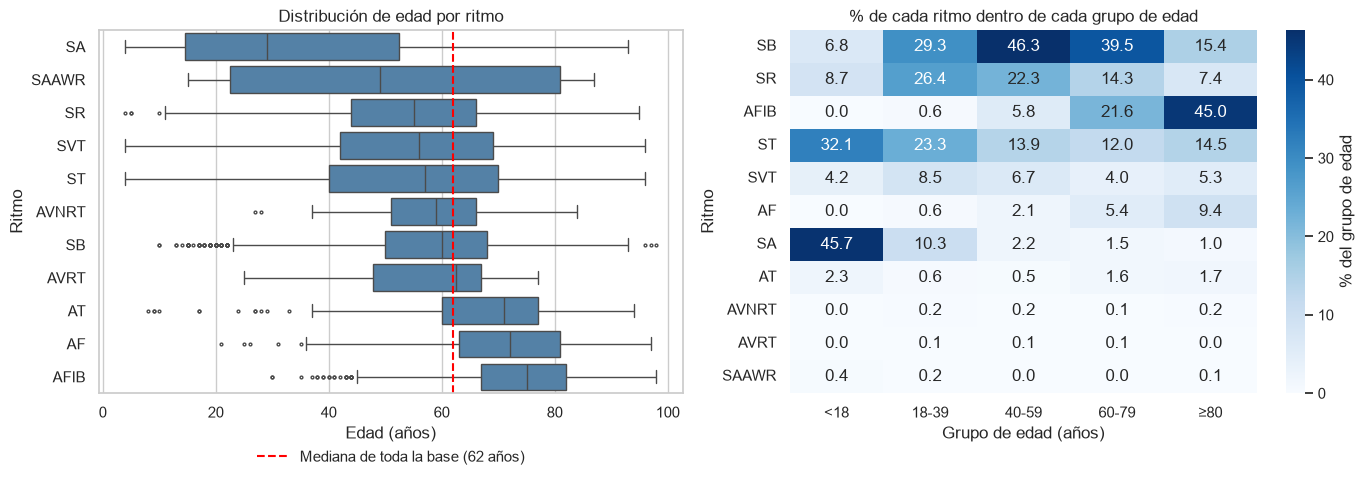

In [8]:
# Edad por ritmo (ordenado por mediana de edad)
orden = df["Rhythm"].value_counts().index
edad_ritmo = (df.groupby("Rhythm")["PatientAge"]
                .describe()[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]]
                .sort_values("50%").round(1))
display(edad_ritmo)

# Grupos de edad
bins = [0, 18, 40, 60, 80, 120]
grupos = ["<18", "18-39", "40-59", "60-79", "≥80"]
df["GrupoEdad"] = pd.cut(df["PatientAge"], bins=bins, labels=grupos, right=False)
display(df["GrupoEdad"].value_counts().loc[grupos].to_frame("n"))

# % de cada ritmo dentro de cada grupo de edad (cada columna suma 100%)
ct_edad = pd.crosstab(df["Rhythm"], df["GrupoEdad"], normalize="columns").loc[orden] * 100
display(ct_edad.round(1))

# Gráficos
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, y="Rhythm", x="PatientAge", order=edad_ritmo.index,
            color="steelblue", fliersize=2, ax=axes[0])
axes[0].axvline(df["PatientAge"].median(), color="red", linestyle="--",
                label=f"Mediana de toda la base ({df['PatientAge'].median():.0f} años)")
axes[0].set_xlabel("Edad (años)")
axes[0].set_ylabel("Ritmo")
axes[0].set_title("Distribución de edad por ritmo")
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False)

sns.heatmap(ct_edad, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "% del grupo de edad"}, ax=axes[1])
axes[1].set_xlabel("Grupo de edad (años)")
axes[1].set_ylabel("Ritmo")
axes[1].set_title("% de cada ritmo dentro de cada grupo de edad")
plt.tight_layout()
plt.show()

Comparando la edad de los pacientes dentro de cada ritmo (mediana y rango intercuartílico) y dividiendo la base en cinco grupos de edad (<18, 18-39, 40-59, 60-79 y ≥80 años) para ver qué porcentaje de cada grupo corresponde a cada ritmo. Así el resultado no depende de que unos grupos tengan más pacientes que otros (por ejemplo, el de 60-79 tiene 4.481 registros y el de <18 solo 265).

Sí hay ritmos claramente asociados a la edad. La fibrilación auricular (AFIB) es el ritmo de pacientes más mayores, con una mediana de 75 años (rango intercuartílico de 67 a 82), seguida del aleteo auricular (AF, 72 años) y la taquicardia auricular (AT, 71 años), todos por encima de la mediana de la base, que es de 62 años. En el otro extremo está la irregularidad sinusal (SA), con una mediana de 29 años y la mitad de sus pacientes entre 14 y 52 años. El ritmo sinusal normal (SR, 55 años), la taquicardia supraventricular (SVT, 56 años), la taquicardia sinusal (ST, 57 años) y la bradicardia sinusal (SB, 60 años) quedan por debajo de la mediana general.

Por grupos de edad, el ritmo más frecuente cambia según la edad:
- En los menores de 18 años predominan la irregularidad sinusal (45,7%) y la taquicardia sinusal (32,1%), y no hay ningún caso de AFIB ni de AF.
- Entre 18 y 39 años los ritmos más comunes son la bradicardia sinusal (29,3%), el ritmo sinusal normal (26,4%) y la taquicardia sinusal (23,3%).
- Entre 40 y 59 años la bradicardia sinusal alcanza su máximo (46,3%), y es también el ritmo más frecuente entre 60 y 79 años (39,5%), seguida de la fibrilación auricular (21,6%).
- En los mayores de 80 años la fibrilación auricular pasa a ser el ritmo más frecuente (45,0%), y la bradicardia sinusal baja a 15,4%.

La tendencia más marcada es la de la fibrilación auricular, que pasa de 0% en menores de 18 años a 0,6%, 5,8%, 21,6% y 45,0% en los grupos siguientes. El aleteo auricular sigue el mismo patrón, aunque con valores más bajos (de 0% a 9,4%). La irregularidad sinusal hace lo contrario: baja de 45,7% en menores de 18 años a 10,3% entre 18 y 39 años, y queda por debajo del 2,5% a partir de los 40. El ritmo sinusal normal también disminuye con la edad, de 26,4% entre 18 y 39 años a 7,4% en los mayores de 80.

En AVNRT, AVRT y SAAWR, como en el punto 2.3, hay muy pocos registros (16, 8 y 7) para concluir algo sobre su relación con la edad. Hay que tener en cuenta que en los menores de 18 años la clasificación como taquicardia o bradicardia sinusal usa los mismos umbrales que en adultos (100 y 60 latidos por minuto). Como la frecuencia cardíaca normal en niños es más alta, parte de la "taquicardia sinusal" de ese grupo podría ser un ritmo normal para su edad. Esto se tendrá en cuenta al elegir el rango de edades en el punto siguiente.

---

**2.5 Los algoritmos de aprendizaje se basan en usar la mayor cantidad
de datos posibles que sean comparables, ¿Qué rango de edades y
arritmias de la base de datos entregada considera que debe usar
para entrenar algoritmos de aprendizaje?**


A partir de la informacion anterior que se extrajo del csv,se eligen los cuatro ritmos con más registros: bradicardia sinusal (SB), ritmo sinusal (SR), fibrilación auricular (AFIB) y taquicardia sinusal (ST), que juntos suman el 85% de la base. Se incluye SR aunque corresponde al ritmo normal, porque un algoritmo que detecta arritmias necesita ejemplos de un ECG normal para aprender a diferenciarlo de uno anormal. En cuanto a la edad, se elige el rango de 40 a 79 años, que corresponde a los grupos de 40-59 y 60-79, los dos con más registros de la base (3.298 y 4.481). En este rango los cuatro ritmos tienen una buena cantidad de datos: 3.298 de SB, 1.374 de SR, 1.162 de AFIB y 997 de ST, para un total de 6.831 registros (64% de la base).

Hay que tener en cuenta que la fibrilación auricular AFIB es el ritmo más frecuente en los mayores de 80 años (45% de ese grupo), así que al excluirlo se pierden 610 registros de AFIB, cerca de un tercio de esa clase. Aun así, se decide no incluirlos para que los cuatro grupos sean comparables en edad: si se agregan, casi la mitad de los mayores de 80 serían AFIB, y el modelo podría asociar la edad con la arritmia en vez de aprender las características de la señal.

---

**2.6 ¿Hay coincidencia entre lo encontrado en literatura y lo encontrado
en la base de datos?**

**Comparación con los artículos**

En el artículo [1], la edad y el sexo por sí solos ya permiten predecir el riesgo de fibrilación auricular con un AUC de 0,67, lo que indica que la FA depende de esas dos variables. Esto coincide con lo que se encontró en la base: AFIB es el ritmo con los pacientes más mayores (mediana de 75 años) y tiene una proporción de hombres (58,5%) algo mayor que la de toda la base.

El artículo [2] trabaja con una base de la misma institución, pero más grande (40.258 pacientes). Sus características son muy parecidas a las de nuestra base: el 56% de sus pacientes son hombres, igual que en la nuestra (55,9%); los grupos de edad más frecuentes son 51-60, 61-70 y 71-80 años, lo que coincide con nuestra mediana de 62 años y con los grupos de 40-59 y 60-79 como los más numerosos; y cerca del 20% de sus registros son ritmo sinusal normal, frente al 17,2% de SR en nuestra base. Además, este artículo agrupa los ritmos en SB, AFIB, taquicardias supraventriculares y SR, que son prácticamente los mismos que elegimos en el apartado anterior.

**Comparación con la literatura clínica**

- **Fibrilación auricular:** la literatura reporta que su prevalencia aumenta con la edad, de 0,12-0,16% en menores de 49 años a 10-17% en mayores de 80, y que es algo más frecuente en hombres, con una relación de 1,2 hombres por cada mujer [4]. En la base se observa la misma tendencia: AFIB pasa de 0% en menores de 18 años a 45% en mayores de 80, con más hombres que mujeres.
- **Taquicardias supraventriculares:** la AVNRT, que es la más común en adultos, afecta con mayor frecuencia a mujeres jóvenes y sanas [5]. En la base, SVT es uno de los pocos ritmos con más mujeres que hombres (52,5% de mujeres), y en AVNRT 12 de los 16 registros son de mujeres, aunque son muy pocos datos para concluir.
- **Irregularidad sinusal:** se presenta sobre todo en niños y adultos jóvenes sanos, y en adultos de 50 a 71 años su prevalencia es menos del 20% de la que tienen los menores de 31 [6]. Esto coincide con la base, donde SA tiene una mediana de 29 años y es el ritmo más frecuente en menores de 18 años (45,7%).

**Diferencias**

La principal diferencia es la magnitud de las prevalencias. En la población general la fibrilación auricular es la arritmia sostenida más común [4], mientras que en en nuestra base el ritmo más frecuente es la bradicardia sinusal (36,5%). Además, el 45% de AFIB en mayores de 80 años es mucho más alto que el 10-17% reportado en la población general. Esto se debe a que la base no es una muestra de la población general, sino de pacientes a los que se les tomó un ECG en un hospital, donde es más probable encontrar arritmias. Por eso los porcentajes de la base sirven para comparar tendencias (qué ritmos aumentan con la edad o predominan en un sexo), pero no para estimar cuántas personas tienen cada arritmia en la población.

---

**2.6 ¿Qué otros análisis propone desde la base de datos?**

A partir de la base de datos se proponen los siguientes análisis:

**1. Pruebas estadísticas** En los puntos anteriores la relación de los ritmos con la edad se describió con porcentajes y gráficos.  Se propone confirmarla comparando la edad entre pares de ritmos: verificar normalidad con Shapiro-Wilk y homocedasticidad con Levene, y según el resultado aplicar la prueba t de Student o de Welch, o la prueba de Mann-Whitney si no se cumple la normalidad. Por ejemplo, comparar la edad de los pacientes con AFIB frente a los de SR permitiría afirmar si la diferencia observada es estadísticamente significativa o si podría deberse al azar.

**2. Comparación de los parámetros del ECG entre ritmos.** La base incluye mediciones como la frecuencia ventricular y auricular, la duración del QRS y el QT corregido, que se podrían comparar entre los ritmos del subconjunto elegido en el punto 2.4 mediante diagramas de caja y el mismo procedimiento de comparación por pares. Se esperaría que la frecuencia ventricular separe claramente SB, SR y ST, ya que estos ritmos se definen por la frecuencia cardíaca (menos de 60, entre 60 y 100, y más de 100 lpm). En AFIB, en cambio, se esperaría una frecuencia ventricular más dispersa y una frecuencia auricular mayor que la ventricular, por la actividad desorganizada de las aurículas. 

**3. Condiciones adicionales** Además del ritmo, muchos pacientes tienen otras condiciones registradas, como bloqueos de rama o alteraciones del segmento ST y de la onda T. En puntos anteriores se encontró que cerca de la mitad de los registros tiene alguna, se propone revisar cómo se distribuyen entre los ritmos elegidos. Esto es importante porque esas condiciones también modifican la forma del ECG, y un modelo podría aprender a reconocerlas en lugar del ritmo. En uno de los estudio,reportaron un desempeño menor en pacientes con otras condiciones (F1 de 0,97 frente a 0,988), por lo que se propone comparar los resultados de los puntos siguientes con y sin estos pacientes. [2]

---

Con base en el análisis descriptivo del punto anterior, seleccionar un subconjunto
de datos para trabajar en los siguientes análisis

---

In [10]:
# Subconjunto de trabajo: SB, SR, AFIB y ST entre 40 y 79 años
ritmos_sel = ["SB", "SR", "AFIB", "ST"]
df_sel = df[df["Rhythm"].isin(ritmos_sel) & df["PatientAge"].between(40, 79)].copy()

print("Registros en el subconjunto:", len(df_sel), f"({100 * len(df_sel) / len(df):.1f}% de la base)")
display(df_sel["Rhythm"].value_counts().to_frame("n"))

Registros en el subconjunto: 6831 (64.2% de la base)


,n
Rhythm,
SB,3298
SR,1374
AFIB,1162
ST,997


**3. Programar las fórmulas 1 al 4 que se encuentran en el artículo. Consultar que significado y utilidad del biespectro**


In [13]:
# Fórmula 1: desviación entre la señal original x(0) y la señal sin tendencia x(n)
def quitar_tendencia(x, n):
    """Ajusta un polinomio de grado n a la señal y lo resta (detrending)."""
    tt = np.arange(len(x))
    tendencia = np.polynomial.Polynomial.fit(tt, x, n)(tt)
    return x - tendencia

def desviacion(x0, xn):
    """delta(n) = (1/k) * sum( (x0(i) - xn(i))^2 ), con k = longitud de la señal."""
    k = len(x0)
    return np.sum((x0 - xn) ** 2) / k

# Fórmula 2: compresión de la señal al rango (0, 1)
def comprimir(x):
    """s(t_k) = (x(t_k) - x_min) / (x_max - x_min)"""
    return (x - x.min()) / (x.max() - x.min())

# Transformada de Fourier de cada segmento (usada por las fórmulas 3 y 4)
def fft_segmentos(x, L):
    """Divide la señal en N segmentos de L muestras y calcula la FFT de cada uno."""
    N = len(x) // L
    if N < 2:
        raise ValueError(f"Con L = {L} solo se forman {N} segmentos; se necesitan al menos 2.")
    segmentos = x[:N * L].reshape(N, L)
    return np.fft.fft(segmentos, axis=1), N

def productos_triples(x, fs, L, fmax=20):
    """X_j(f1) * X_j(f2) * X_j*(f1+f2) para cada segmento j y cada par (f1, f2) entre 0 y fmax."""
    X, N = fft_segmentos(x, L)
    k = np.arange(1, int(fmax * L / fs) + 1)  # índices de las frecuencias (sin f = 0)
    K1, K2 = np.meshgrid(k, k, indexing="ij")
    prod = X[:, K1] * X[:, K2] * np.conj(X[:, K1 + K2])
    f = k * fs / L
    return f, prod, N

# Fórmula 3: biespectro
def biespectro(x, fs, L, fmax=20):
    """b(f1, f2) = sum_j X_j(f1) X_j(f2) X_j*(f1 + f2)
    Devuelve (frecuencias, matriz b, número de segmentos N)."""
    f, prod, N = productos_triples(x, fs, L, fmax)
    return f, prod.sum(axis=0), N

# Fórmula 4: bicoherencia
def bicoherencia(x, fs, L, fmax=20):
    """B(f1, f2) = |sum_j X_j(f1) X_j(f2) X_j*(f1+f2)| / sum_j |X_j(f1) X_j(f2) X_j*(f1+f2)|
    Devuelve (frecuencias, matriz B, número de segmentos N)."""
    f, prod, N = productos_triples(x, fs, L, fmax)
    return f, np.abs(prod.sum(axis=0)) / np.abs(prod).sum(axis=0), N

Las cuatro fórmulas del artículo [7] se programaron como funciones, para aplicarlas más adelante a las señales de la base.

**Fórmula 1: desviación por la eliminación de la tendencia**

$$\delta(n) = \frac{1}{k}\sum_{i=1}^{k}\left(x^{(0)}(i) - x^{(n)}(i)\right)^2$$

Las señales de ECG pueden tener una tendencia global causada por movimientos del paciente o por fluctuaciones de voltaje del equipo, por lo que se debe quitar antes de procesarlas. Para eso se ajusta un polinomio de grado *n* y se resta de la señal original $x^{(0)}$, y la fórmula mide la desviación promedio entre la señal original y la señal sin tendencia $x^{(n)}$, donde *k* es la longitud de las señales. El artículo encuentra que δ(n) se satura para *n* mayor que 20, y por eso usa n = 20 en todos los casos.

**Fórmula 2: compresión** 

$$s(t_k) = \frac{x(t_k) - x_{min}}{x_{max} - x_{min}}$$

Lleva todos los valores de la señal al rango entre 0 y 1 sin alterar su información, para comparar señales de distintos pacientes de manera uniforme. Aquí $x_{max}$ y $x_{min}$ son el máximo y el mínimo de la señal sin tendencia.

**Fórmula 3: biespectro**

$$b(f_1, f_2) = \sum_{j=1}^{N} X_j(f_1)\,X_j(f_2)\,X_j^*(f_1 + f_2)$$

La señal se divide en *N* segmentos y se calcula la transformada de Fourier $X_j$ de cada uno con el algoritmo FFT. Para cada par de frecuencias (f1, f2) se multiplica la componente en f1, la componente en f2 y el conjugado de la componente en f1 + f2, y se suma sobre los *N* segmentos.

**Fórmula 4: bicoherencia** 

$$B(f_1, f_2) = \frac{\left|\sum_{j=1}^{N} X_j(f_1)\,X_j(f_2)\,X_j^*(f_1 + f_2)\right|}{\sum_{j=1}^{N}\left|X_j(f_1)\,X_j(f_2)\,X_j^*(f_1 + f_2)\right|}$$

Es el biespectro normalizado para que su magnitud quede entre 0 y 1. Se puede calcular a partir de una sola señal, y como en el artículo se calcula en el rango de 0 a 20 Hz, donde se concentra la potencia del ECG.

**Longitud de los segmentos.** El artículo usa segmentos de 8192 muestras, pero sus registros tienen 60 s a 1000 Hz. Los de esta base tienen 5000 muestras (10 s a 500 Hz), con las que no se puede formar ni un segmento de ese tamaño. Por eso la longitud *L* de los segmentos es un parámetro de las funciones, y se usará L = 1000 (2 s, N = 5 segmentos y 0,5 Hz de resolución en frecuencia). Es lo único que se adapta respecto al artículo.

**¿Qué es un biespectro? y ¿Cuál es su utilidad?**

El espectro de potencia indica cuánta potencia tiene una señal en cada frecuencia, pero no dice nada sobre la relación de fase entre ellas. El biespectro, que es la transformada de Fourier de la correlación de tercer orden, sí lo hace: mide el acoplamiento cuadrático de fase entre las frecuencias f1, f2 y f1 + f2, y permite detectar procesos no lineales y no gaussianos [8]. Su versión normalizada entre 0 y 1 es la bicoherencia, que indica qué proporción de la energía de cada par de frecuencias está acoplada en fase [8].

En el ECG sirve para distinguir un ritmo normal de uno patológico. En personas sanas, la frecuencia del pulso (cerca de 1 Hz) concentra la mayor potencia y tiene bicoherencia significativa con muchas otras frecuencias; en pacientes, ese acoplamiento se reduce y la potencia se redistribuye hacia frecuencias más altas [8]. Además, características calculadas a partir del biespectro, como su magnitud, sus entropías y la fase, han permitido separar complejos QRS normales de cinco clases de arritmias en la base MIT-BIH [9].

---

**4. Para cada señal extraer la frecuencia que contiene la máxima potencia**

True 10646 archivos .csv


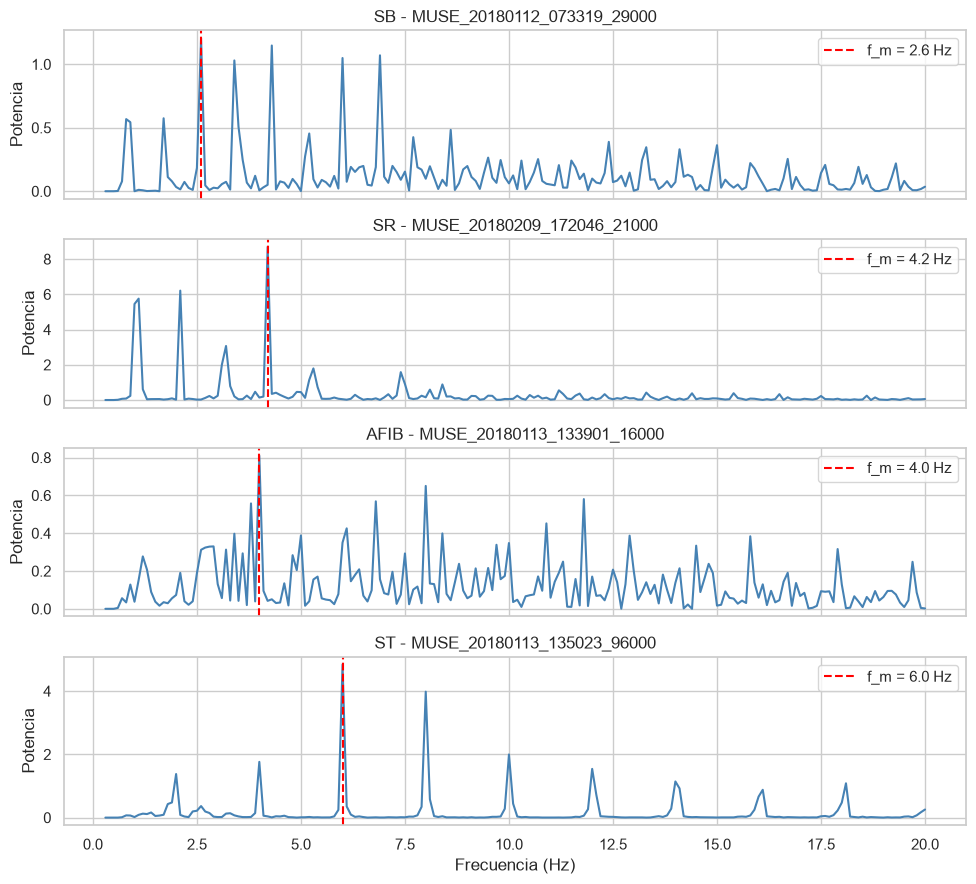

In [19]:
SIGNALS_DIR = Path(r"C:\Users\PAULA CAMILA\OneDrive - Universidad de Antioquia\Escritorio\ECGDataDenoised")
print(SIGNALS_DIR.exists(), len(list(SIGNALS_DIR.glob("*.csv"))), "archivos .csv")
FS = 500  
LEADS = ["I", "II", "III", "aVR", "aVL", "aVF", "V1", "V2", "V3", "V4", "V5", "V6"]
LEAD_INDEX = LEADS.index("II")  

def cargar_senal(filename):
    """Carga la derivación II de un registro de ECGDataDenoised (filename sin la extensión .csv)."""
    senal = pd.read_csv(SIGNALS_DIR / f"{filename}.csv", header=None)
    return senal.iloc[:, LEAD_INDEX].values

def preprocesar(x, grado=20):
    """Preprocesamiento del artículo: quitar la tendencia (fórmula 1) y comprimir (fórmula 2)."""
    return comprimir(quitar_tendencia(x, grado))

def espectro_potencia(x, fs):
    """Espectro de potencia con la FFT: P(f) = |X(f)|^2 / N."""
    X = np.fft.rfft(x)
    f = np.fft.rfftfreq(len(x), d=1 / fs)
    return f, np.abs(X) ** 2 / len(x)

def frecuencia_max_potencia(x, fs, fmin=0.3, fmax=20):
    """Frecuencia con máxima potencia (f_m). Se descartan las frecuencias menores de 0.3 Hz
    para evitar artefactos como la deriva de la línea base, como en el artículo."""
    f, P = espectro_potencia(x, fs)
    zona = (f >= fmin) & (f <= fmax)
    return f[zona][np.argmax(P[zona])]

# Demostración: una señal de cada ritmo del subconjunto de trabajo
ritmos_sel = ["SB", "SR", "AFIB", "ST"]
fig, axes = plt.subplots(len(ritmos_sel), 1, figsize=(10, 9), sharex=True)
for ax, ritmo in zip(axes, ritmos_sel):
    archivo = df_sel[df_sel["Rhythm"] == ritmo]["FileName"].iloc[0]
    s = preprocesar(cargar_senal(archivo))
    f, P = espectro_potencia(s, FS)
    fm = frecuencia_max_potencia(s, FS)
    zona = (f >= 0.3) & (f <= 20)
    ax.plot(f[zona], P[zona], color="steelblue")
    ax.axvline(fm, color="red", linestyle="--", label=f"f_m = {fm:.1f} Hz")
    ax.set_ylabel("Potencia")
    ax.set_title(f"{ritmo} - {archivo}")
    ax.legend(loc="upper right")
axes[-1].set_xlabel("Frecuencia (Hz)")
plt.tight_layout()
plt.show()

**5. Para cada señal sumar el número de frecuencias que son significativas para bicoherencia cuales tienen un valor superior a √9.22⋅𝑁**

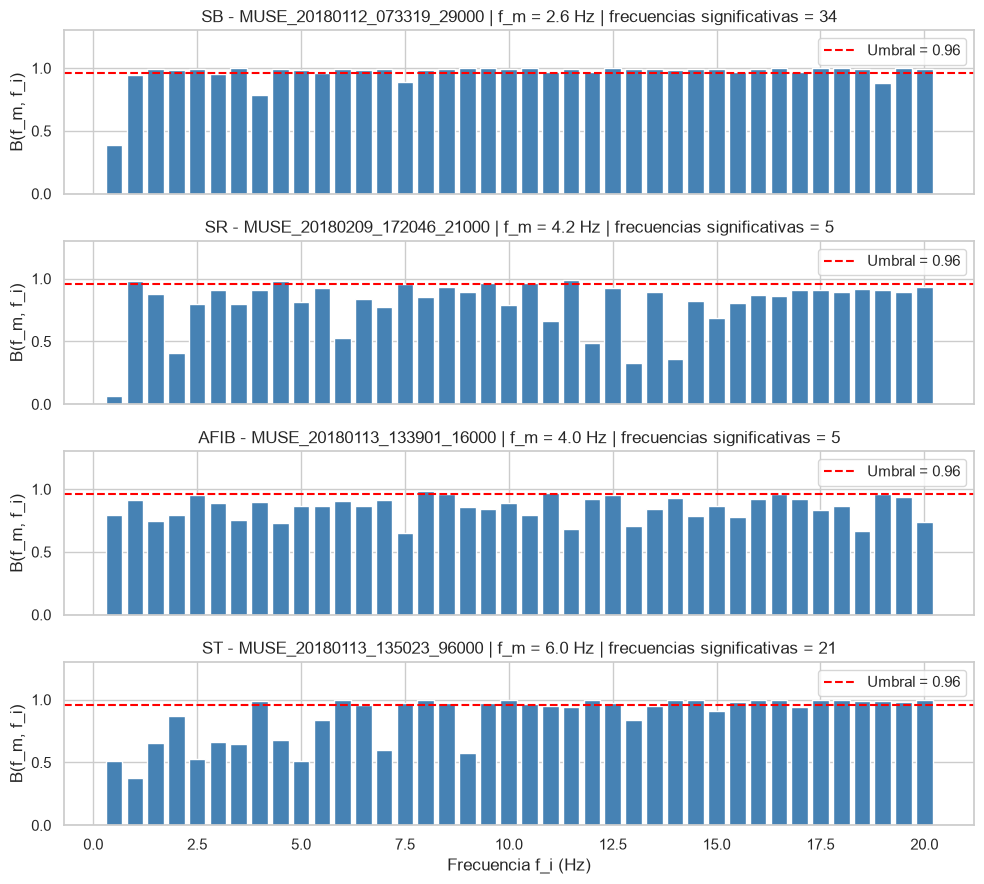

In [20]:
def umbral_significancia(N):
    """Umbral de significancia de la bicoherencia: sqrt(9.2 / (2N)), con N = número de segmentos."""
    return np.sqrt(9.2 / (2 * N))

def suma_frecuencias_significativas(x, fs, L, f_ref):
    """Número de frecuencias f_i cuya bicoherencia con la frecuencia de referencia f_ref
    supera el umbral, es decir, B(f_ref, f_i) > sqrt(9.2 / (2N)).
    La frecuencia de referencia se aproxima a la frecuencia más cercana de la malla de la bicoherencia."""
    f, B, N = bicoherencia(x, fs, L)
    umbral = umbral_significancia(N)
    i = np.argmin(np.abs(f - f_ref))
    return int(np.sum(B[i, :] > umbral))

L = 1000  # muestras por segmento, igual que en el punto 3

# Demostración: una señal de cada ritmo del subconjunto de trabajo
fig, axes = plt.subplots(len(ritmos_sel), 1, figsize=(10, 9), sharex=True)
for ax, ritmo in zip(axes, ritmos_sel):
    archivo = df_sel[df_sel["Rhythm"] == ritmo]["FileName"].iloc[0]
    s = preprocesar(cargar_senal(archivo))
    fm = frecuencia_max_potencia(s, FS)
    f, B, N = bicoherencia(s, FS, L)
    umbral = umbral_significancia(N)
    i = np.argmin(np.abs(f - fm))
    n_sig = suma_frecuencias_significativas(s, FS, L, fm)
    ax.bar(f, B[i, :], width=0.4, color="steelblue")
    ax.axhline(umbral, color="red", linestyle="--", label=f"Umbral = {umbral:.2f}")
    ax.set_ylim(0, 1.3)
    ax.set_ylabel("B(f_m, f_i)")
    ax.set_title(f"{ritmo} - {archivo} | f_m = {fm:.1f} Hz | frecuencias significativas = {n_sig}")
    ax.legend(loc="upper right")
axes[-1].set_xlabel("Frecuencia f_i (Hz)")
plt.tight_layout()
plt.show()

Aquí se aplica el mismo procedimiento: para cada señal se calcula la bicoherencia (punto 3) y se cuenta cuántas frecuencias $f_i$, entre 0 y 20 Hz, cumplen $B(f_m, f_i) > \sqrt{9.2/(2N)}$. Como frecuencia de referencia se usa la frecuencia de máxima potencia $f_m$ del punto 4, por tres razones:

1. **Es una frecuencia que se obtiene de la propia señal.** La frecuencia del pulso podría estimarse a partir de la columna `VentricularRate` de la base, pero ese valor es una medición del equipo y no de la señal analizada, mientras que $f_m$ sale directamente del espectro de cada registro.
2. **El artículo también usa $f_m$ como referencia en la bicoherencia.** Además de contar los pares con la frecuencia del pulso $f_0$, el artículo aplica un filtro de bicoherencia usando la frecuencia del pico principal $f_m$ [7]. En personas sanas ambas coinciden, porque el pulso es el componente con más potencia [7].
3. **Conecta los puntos 4 y 5.** La tabla final del proyecto reúne $f_m$ y el número de frecuencias significativas de cada señal, y usar la misma frecuencia en ambos permite relacionar las dos medidas.

Como limitación, en las señales de esta base $f_m$ puede caer en un armónico del pulso (punto 4), por lo que el conteo mide el acoplamiento de fase con el componente dominante del espectro y no necesariamente con el pulso. La bicoherencia se calcula sobre una malla de 0,5 Hz, por lo que $f_m$ se aproxima a la frecuencia más cercana de esa malla.

---

**6. Crear una rutina que aplique sobre todos los archivos de la base de datos las rutinas 3 al 5 y almacene los resultados en un dataframe donde se pueda ver registro, tipo de patología, la frecuencia de máxima potencia (fMP) y la suma de frecuencias significativas en bicoherencia (sFSB).**

| Registro | Estado | fMP | sFSB |
|----------|--------|-----|------|
|          |        |     |      |

In [22]:
from tqdm.auto import tqdm

def procesar_registro(filename):
    """Aplica las rutinas de los puntos 3 a 5 a un registro y devuelve (fMP, sFSB)."""
    x = cargar_senal(filename)
    if not np.all(np.isfinite(x)) or np.ptp(x) == 0:
        raise ValueError("señal con valores no válidos o constante")
    s = preprocesar(x)                         # punto 3: quitar tendencia y comprimir
    fm = frecuencia_max_potencia(s, FS)        # punto 4: frecuencia de máxima potencia
    n_sig = suma_frecuencias_significativas(s, FS, L, fm)  # punto 5: frecuencias significativas
    return fm, n_sig

BASE_PROCESO = df_sel  # subconjunto de trabajo (cambiar a df para procesar toda la base)
RUTA_RESULTADOS = Path("resultados_fmp_sfsb.csv")
RECALCULAR = False  # True para volver a procesar todos los registros

if RUTA_RESULTADOS.exists() and not RECALCULAR:
    resultados = pd.read_csv(RUTA_RESULTADOS)
    print(f"Resultados cargados desde {RUTA_RESULTADOS}")
else:
    filas, errores = [], []
    for _, fila in tqdm(BASE_PROCESO.iterrows(), total=len(BASE_PROCESO)):
        try:
            fm, n_sig = procesar_registro(fila["FileName"])
        except Exception as e:
            fm, n_sig = np.nan, np.nan
            errores.append((fila["FileName"], str(e)))
        filas.append({"Registro": fila["FileName"], "Estado": fila["Rhythm"], "fMP": fm, "sFSB": n_sig})
    resultados = pd.DataFrame(filas)
    resultados.to_csv(RUTA_RESULTADOS, index=False)
    print(f"Registros procesados: {len(resultados) - len(errores)} | con error: {len(errores)}")
    if errores:
        display(pd.DataFrame(errores, columns=["Registro", "Error"]).head())

display(resultados.head())
print(resultados.shape, "| valores faltantes:", resultados[["fMP", "sFSB"]].isna().sum().to_dict())

100%|██████████| 6831/6831 [04:53<00:00, 23.26it/s]

Registros procesados: 6830 | con error: 1


,Registro,Error
0,MUSE_20180113_124215_52000,Con L = 1000 solo se forman 1 segmentos; se ne...


,Registro,Estado,fMP,sFSB
0,MUSE_20180112_073319_29000,SB,2.6,34.0
1,MUSE_20180113_121940_44000,SB,3.6,36.0
2,MUSE_20180112_120347_79000,SB,3.8,17.0
3,MUSE_20180209_172046_21000,SR,4.2,5.0
4,MUSE_20180114_075128_92000,SB,1.0,34.0


(6831, 4) | valores faltantes: {'fMP': 1, 'sFSB': 1}


**7. Para las señales de análisis del punto 2 aplicar las rutinas del punto 3 al
5 y hacer un informe que permita evidenciar las diferencias entre las
señales las diferentes arritmias utilizando las herramientas de estadística
descriptiva**

**Referencias**

[1] M. Gadaleta *et al.*, "Prediction of atrial fibrillation from at-home single-lead ECG signals without arrhythmias," *npj Digit. Med.*, vol. 6, no. 1, pp. 1–9, Dic. 2023, doi: 10.1038/s41746-023-00966-w.

[2] J. Zheng *et al.*, "Optimal multi-stage arrhythmia classification approach," *Sci. Rep.*, vol. 10, Art. no. 2898, Feb. 2020, doi: 10.1038/s41598-020-59821-7.

[3] L.-R. Liu *et al.*, "An arrhythmia classification approach via deep learning using single-lead ECG without QRS wave detection," *Heliyon*, vol. 10, no. 5, Art. no. e27200, 2024, doi: 10.1016/j.heliyon.2024.e27200.

[4] M. Zoni-Berisso, F. Lercari, T. Carazza y S. Domenicucci, "Epidemiology of atrial fibrillation: European perspective," *Clin. Epidemiol.*, vol. 6, pp. 213–220, 2014, doi: 10.2147/CLEP.S47385.

[5] R. A. Colucci, M. J. Silver y J. Shubrook, "Common types of supraventricular tachycardia: Diagnosis and management," *Am. Fam. Physician*, vol. 82, no. 8, pp. 942–952, Oct. 2010.

[6] M. P. Soos y D. McComb, "Sinus arrhythmia," en *StatPearls*. Treasure Island, FL, EE. UU.: StatPearls Publishing. [En línea].

[7] https://arxiv.org/pdf/1809.08451

[8] Y. Kotriwar, S. Kachhara, K. P. Harikrishnan y G. Ambika, "Higher order spectral analysis of ECG signals," arXiv:1809.08451, Sep. 2018.

[9] "Robust multiple cardiac arrhythmia detection through bispectrum analysis," [REVISTA], vol. [X], 2011 https://www.sciencedirect.com/science/article/abs/pii/S0957417410014296?via%3Dihub